# Which grid types are there?

The classification clusters the grids of the sample on a few key figures (chosen in
[01_sample_and_key_figures](01_sample_and_key_figures.ipynb)) and names the real grid closest to the centre of each
cluster as its representative. This notebook shows how many clusters the data support, whether k-means and a Gaussian
mixture model agree, how the clusters differ and what their representative grids look like.

**Needs:** a classification run (`pylovo-classify`, see [Classifying grids](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html)), the `notebooks` extra and a
`.env` that points to the database (see `notebook_tutorials/README.md`). The notebook only reads. The stored outputs
show a classification of 501 Bavarian PLZ, drawn from LV version 1 of the pylovo results database.

In [1]:
# Parameters
classification_id = None  # None: CLASSIFICATION_VERSION of config_classification.yaml
version_id = None  # None: VERSION_ID of config_generation_lv.yaml
algorithm = "kmeans"  # clustering shown after the comparison: "kmeans" or "gmm" (tied covariance)
n_clusters = None  # None: the numbers of clusters stored with the classification

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from pylovo.classification.clustering.clustering_algorithms import gmm_tied_clustering, kmeans_clustering
from pylovo.classification.database_communication.database_communication import DatabaseCommunication
from pylovo.config_loader import NO_OF_CLUSTERS_ALLOWED
from pylovo.database.database_client import DatabaseClient
from pylovo.plotting.classification import (
    plot_ch_index_for_clustering_algos,
    plot_clusters_in_parameter_space,
    plot_clusters_per_regiostar_class,
    plot_db_index_for_clustering_algos,
    plot_percentage_of_clusters,
    plot_radar_graph,
    plot_representative_grids,
)

plt.rcParams["figure.dpi"] = 80  # moderate resolution of the stored figures
dc = DatabaseCommunication(classification_id, version_id)
choices = dc.get_classification_choices()
parameters = choices["list_of_clustering_parameters"]
grids = dc.municipal_register_with_clustering_parameters_for_classification_version()
print(f"Classification {dc.classification_id}, version {dc.version_id}: {len(grids)} grids in {grids['plz'].nunique()} PLZ")
choices

Database connection is constructed. 


Classification 1, version 1: 26786 grids in 501 PLZ


{'list_of_clustering_parameters': ['no_house_connections_per_branch',
  'no_household_equ_per_branch',
  'avg_trafo_dis',
  'no_branches'],
 'n_clusters_kmeans': 5,
 'n_clusters_gmm': 5,
 'additional_filtering': False}

## How many clusters do the data support?

`pylovo-classify` compares the numbers of `NO_OF_CLUSTERS_ALLOWED` with the Calinski-Harabasz index and takes the best
one of k-means and of the GMM with tied covariance ([Step 6b](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-6b-number-of-clusters)). The Davies-Bouldin
index is a second opinion.

,algorithm,no_clusters_ch,ch_index,no_clusters_db,db_index
0,kmeans,5,10779.732450,5,0.986780
1,gmm_full,3,6860.578063,4,1.396062
2,gmm_diag,5,6429.460804,5,1.530105
3,gmm_tied,5,9237.728256,6,0.908420
4,gmm_sph,6,8797.465605,6,1.155075


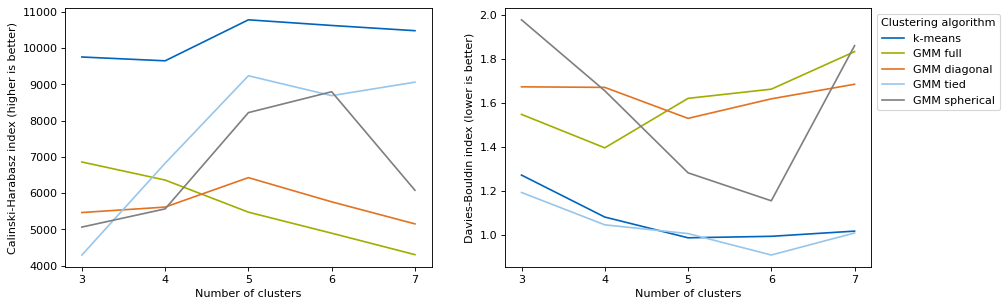

In [3]:
fig, (ch_ax, db_ax) = plt.subplots(1, 2, figsize=(13, 4.2))
ch = plot_ch_index_for_clustering_algos(grids, NO_OF_CLUSTERS_ALLOWED, parameters, ax=ch_ax, legend=False)
db = plot_db_index_for_clustering_algos(grids, NO_OF_CLUSTERS_ALLOWED, parameters, ax=db_ax)
ch.merge(db, on="algorithm", suffixes=("_ch", "_db"))

The Calinski-Harabasz index rewards compact clusters that lie far apart (higher is better), the Davies-Bouldin
index penalises clusters that overlap (lower is better). Here both indices give k-means 5 clusters; for the tied
GMM the Calinski-Harabasz index gives 5, the Davies-Bouldin index 6. k-means has the highest Calinski-Harabasz
index of all algorithms, the tied GMM with 6 clusters the lowest Davies-Bouldin index. The run stored 5 and 5
(printed above).

## Do k-means and the GMM find the same clusters?

Both algorithms cluster the standardised key figures; the GMM with tied covariance allows elongated clusters, all
of the same shape.

In [4]:
n_kmeans, n_gmm = (n_clusters, n_clusters) if n_clusters else (choices["n_clusters_kmeans"], choices["n_clusters_gmm"])
kmeans_grids, kmeans_representatives = kmeans_clustering(grids.copy(), parameters, n_kmeans)
gmm_grids, gmm_representatives = gmm_tied_clustering(grids.copy(), parameters, n_gmm)
print(f"Adjusted Rand index: {adjusted_rand_score(kmeans_grids['clusters'], gmm_grids['clusters']):.2f}")
pd.crosstab(kmeans_grids["clusters"], gmm_grids["clusters"], rownames=["k-means"], colnames=["GMM"])

converged: True
no of iterations 8
Adjusted Rand index: 0.54


GMM,0,1,2,3,4
k-means,,,,,
0,5,10323,0,0,2
1,1617,476,51,0,2
2,4,2502,4684,0,58
3,15,357,630,1996,126
4,0,867,69,0,3002


The adjusted Rand index is 1 for identical clusterings and about 0 for random ones. The table counts the grids per
pair of clusters. Here k-means cluster 0 (the small grids) lies almost entirely in GMM cluster 1, which also takes a
third of k-means cluster 2; k-means clusters 1, 3 and 4 correspond mainly to GMM clusters 0, 3 and 4. Both
algorithms number their clusters by the households of the representative grid, so the same number need not be the
same cluster.

## Where do the clusters lie?

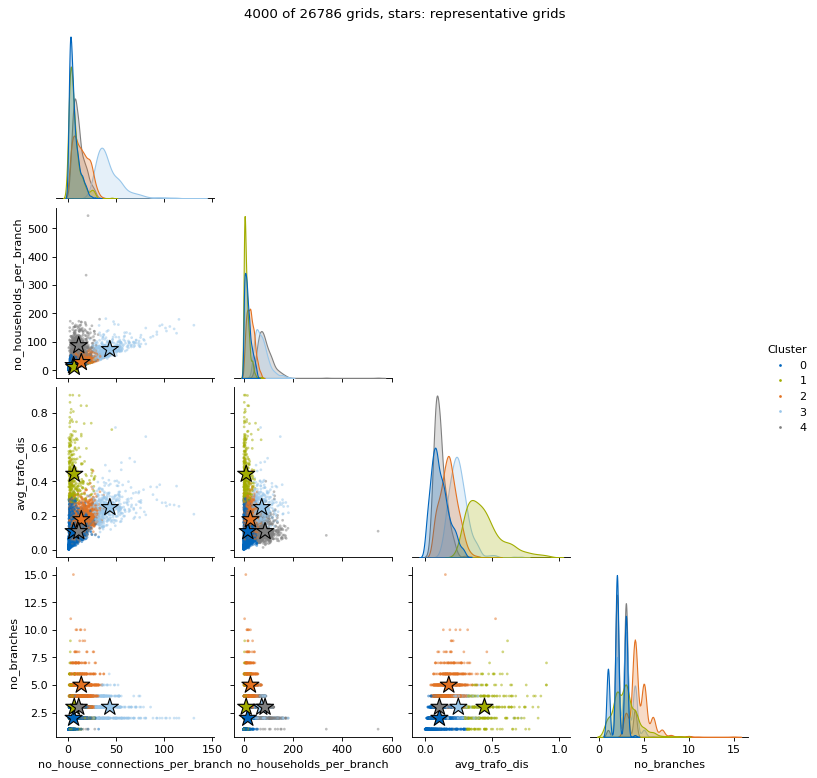

In [5]:
clustered, representatives = {"kmeans": (kmeans_grids, kmeans_representatives),
                              "gmm": (gmm_grids, gmm_representatives)}[algorithm]
fig = plot_clusters_in_parameter_space(clustered, parameters, representatives)

Every point is a grid in the colour of its cluster, the stars are the representative grids. In the stored output
(k-means) the clusters separate along single key figures: cluster 1 (green) by the long paths from the transformer,
cluster 3 (light blue) by many house connections per feeder, cluster 4 (grey) by many household equivalents per
feeder with few connections (apartment buildings), cluster 2 (orange) by more feeders. Cluster 0 (blue) holds the small grids
close to the origin.

## How common is each cluster, and where?

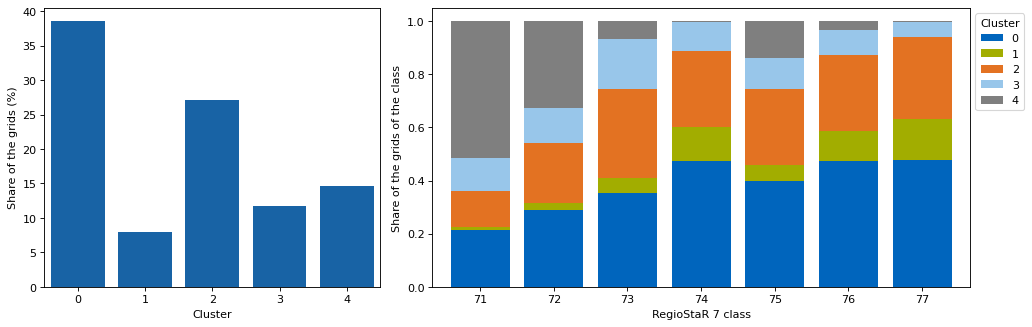

In [6]:
fig, (share_ax, class_ax) = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=[1, 1.6])
plot_percentage_of_clusters(clustered, ax=share_ax)
plot_clusters_per_regiostar_class(clustered, ax=class_ax)
fig.tight_layout()

Left: the small grids of cluster 0 make up almost 40 % of all grids, the long rural grids of cluster 1 8 %.
Right: the mix in each RegioStaR 7 class. In the metropolis (71) half of the grids belong to cluster 4, the dense
grids with many household equivalents per feeder; towards the rural classes the small grids (0) and the long grids (1) take
over.

## What distinguishes the clusters?

The median of every cluster describes its typical grid; the representative is the real grid closest to the cluster
centre in the standardised clustering parameters.

In [7]:
columns = list(dict.fromkeys(parameters + ["no_house_connections", "no_households", "no_branches", "transformer_mva",
                                           "cable_length_km", "max_trafo_dis"]))
clustered.groupby("clusters")[columns].median().round(3)

,no_house_connections_per_branch,no_household_equ_per_branch,avg_trafo_dis,no_branches,no_house_connections,no_households,transformer_mva,cable_length_km,max_trafo_dis
clusters,,,,,,,,,
0,5.000,14.500,0.098,2.0,11.0,20.0,0.40,0.550,0.200
1,4.550,8.385,0.411,3.0,13.0,17.0,0.25,2.459,0.889
2,12.750,25.932,0.175,4.0,56.0,101.0,0.40,2.151,0.379
3,39.667,66.988,0.242,3.0,118.0,195.0,0.63,3.999,0.506
4,9.667,80.684,0.102,3.0,24.0,206.0,0.63,0.941,0.209


In [8]:
representatives.set_index("clusters")[["plz", "kcid", "bcid"] + columns]

,plz,kcid,bcid,no_house_connections_per_branch,no_household_equ_per_branch,avg_trafo_dis,no_branches,no_house_connections,no_households,transformer_mva,cable_length_km,max_trafo_dis
clusters,,,,,,,,,,,,
0,92224,9,6,6.000000,17.139092,0.107787,2,12,5,0.40,0.653359,0.276271
1,95460,2,11,6.666667,10.666667,0.442682,3,20,32,0.25,3.349982,0.927889
2,96049,6,8,14.000000,27.800000,0.177519,5,70,139,0.40,2.290401,0.309995
3,86899,3,29,43.666667,73.471575,0.248262,3,131,214,0.63,4.201043,0.389943
4,80803,1,18,11.333333,87.000000,0.107897,3,34,261,0.63,1.023543,0.197713


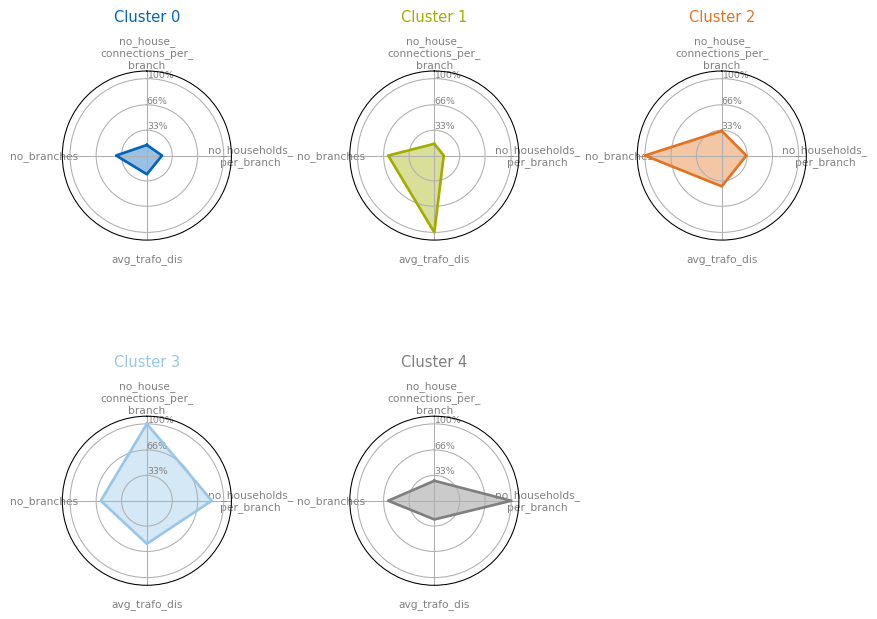

In [9]:
fig = plot_radar_graph(representatives, parameters, figsize=(10, 7.5))

The clusters differ in size, density and length. Here the median grid of cluster 0 has 11 house connections on
0.55 km of cable, cluster 1 is a long rural grid (mean path 0.41 km, 250 kVA), cluster 2 a medium grid on four
feeders, cluster 3 a large grid of 118 house connections at 630 kVA, cluster 4 a short, dense grid of 24 house
connections with 206 households. The radar shows every clustering parameter of a representative relative to the largest
representative.

## What do the representative grids look like?

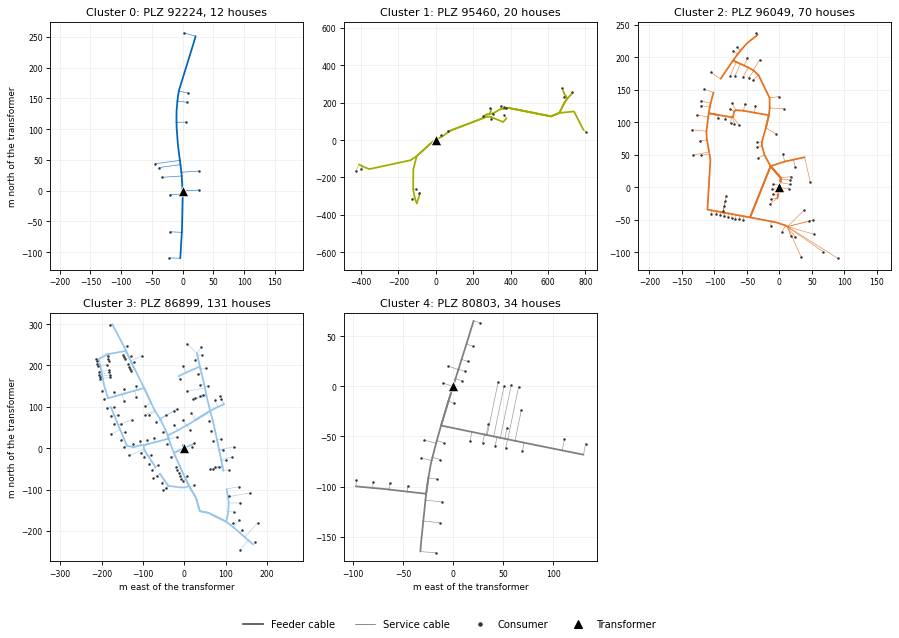

In [10]:
with DatabaseClient() as client:
    nets = [client.read_net_db(int(r.plz), int(r.kcid), int(r.bcid), version_id=dc.version_id)
            for r in representatives.itertuples()]
titles = [f"Cluster {r.clusters}: PLZ {r.plz}, {r.no_house_connections} houses" for r in representatives.itertuples()]
fig = plot_representative_grids(nets, titles)

Each panel is the representative grid of one cluster around its transformer (triangle): feeder cables thick,
service cables thin, consumers as dots. The axes are in metres, and every panel has its own scale: the rural grid
of cluster 1 reaches 800 m from its station, the urban grid of cluster 4 (Munich) stays within 150 m.
`plot_representative_grids(nets, titles, same_scale=True)` draws all panels at the extent of the largest grid.

## Next

The result of the run is stored per transformer in `pylovo.transformer_classified` and, with the grid data, in the view
`pylovo.transformer_classified_with_grid`: add it to QGIS and colour it by `kmeans_clusters` or `gmm_clusters`
([Step 7](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-7-clustering-and-result)). A pandapower net of any grid:
`DatabaseClient().read_net_db(plz, kcid, bcid)`.